# TP - Construire et entraîner un MLP avec TensorFlow/Keras

Ce TP applique le cours avec les fonctions prédéfinies de Keras. Vous construisez le réseau, choisissez ses réglages, lancez l’apprentissage et interprétez les résultats. TensorFlow calcule les gradients automatiquement. Un petit MLP NumPy est fourni au début pour lire son fonctionnement interne. Les exercices d’entraînement utilisent ensuite Keras, sans écriture ni dérivation des gradients.

**Objectifs :** utiliser `Sequential`, `Dense`, `compile`, `fit`, `predict` et `evaluate`, puis appliquer les activations, les optimisateurs, les lots, la régularisation et l’arrêt précoce. Vous sauvegarderez aussi un modèle utilisable dans une application.

**À rendre :** ce notebook complété, avec ses sorties, les réponses Q1-Q14 et le petit travail autonome final. Exécuter les cellules dans l’ordre. Les cellules « À COMPLÉTER » doivent être complétées avant de retirer leur `raise NotImplementedError`. Le notebook ne nécessite aucun fichier Python externe.


## Préparation de l’environnement
Ouvrir le notebook dans Google Colab ou Jupyter. Dans Colab, vérifier d’abord les imports. En local, si une bibliothèque manque, exécuter `%pip install tensorflow numpy matplotlib scikit-learn pandas`, puis redémarrer le kernel si nécessaire.

Les images viennent du jeu `digits` inclus dans scikit-learn. Aucun téléchargement d’images n’est nécessaire après installation. Le TP fonctionne sur CPU. La dernière partie charge Dry Bean depuis UCI avec ucimlrepo. Exécuter la cellule suivante et relever les versions utilisées.


In [1]:
# --- Étape 0 : imports et reproductibilité ---------------------------------
import numpy as np                              # calcul numérique
import matplotlib.pyplot as plt                 # graphiques
import tensorflow as tf                         # moteur de calcul (gradients automatiques)
from tensorflow import keras                    # API haut niveau pour construire des réseaux
from tensorflow.keras import layers             # couches (Dense, Dropout, BatchNormalization...)
from sklearn.datasets import load_digits        # jeu de chiffres manuscrits 8x8
from sklearn.model_selection import train_test_split   # découpage train/validation/test
from sklearn.preprocessing import StandardScaler       # standardisation des variables
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42                                       # graine : même résultat à chaque exécution
keras.utils.set_random_seed(SEED)               # fixe les graines Python, NumPy et TensorFlow
print("TensorFlow :", tf.__version__, "Keras :", getattr(keras, "__version__", "incluse dans TensorFlow"))
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})   # style des figures

I0000 00:00:1792659999.683985    5977 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792659999.684534    5977 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792660000.920117    5977 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792660000.920450    5977 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow : 2.21.0 Keras : 3.15.1


## Lecture d’un petit MLP NumPy : ce qui se passe à l’intérieur

Le premier code est **entièrement fourni**. Il reprend XNOR sur les quatre couples binaires avec un réseau 2-3-1. Exécuter la cellule, lire les commentaires et observer les probabilités avant et après apprentissage. Il n’est pas demandé d’écrire ni de dériver les gradients.

**Questions de lecture :**
- Où les entrées traversent-elles les deux couches ?
- Où le programme compare-t-il les prédictions aux cibles ?
- Quelles lignes transmettent l’erreur vers la couche cachée ?
- Quelles lignes changent effectivement les poids et biais ?
- Quelle différence entre les méthodes `forward` et `fit` ?

À partir de la partie suivante, l’entraînement sur les images utilise **les fonctions prédéfinies de Keras**, qui automatisent ces étapes. Les étudiants construisent et configurent les réseaux sans réimplémenter leur apprentissage.


x1 x2 | cible | probabilité initiale | finale | décision
[[0.         0.         1.         0.5        0.99907544 1.        ]
 [0.         1.         0.         0.41086294 0.00300052 0.        ]
 [1.         0.         0.         0.60371855 0.00306072 0.        ]
 [1.         1.         1.         0.52542099 0.99673409 1.        ]]


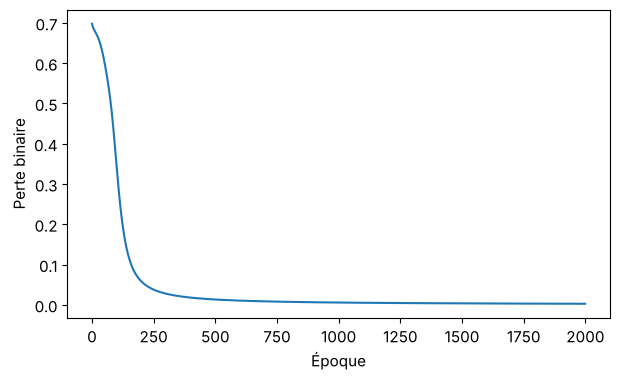

In [2]:
# Code fourni : exécuter et lire, sans le compléter.
# Réseau 2-3-1 écrit "à la main" avec NumPy pour comprendre ce que Keras automatise.
class MiniMLP:
    def __init__(self, seed=5):
        rng = np.random.default_rng(seed)
        # Couche cachée : 2 entrées -> 3 neurones. Poids aléatoires de faible amplitude.
        self.W1 = rng.normal(0, 1/np.sqrt(2), (2, 3))
        self.b1 = np.zeros((1, 3))                       # biais de la couche cachée
        # Couche de sortie : 3 neurones cachés -> 1 sortie
        self.W2 = rng.normal(0, 1/np.sqrt(3), (3, 1))
        self.b2 = np.zeros((1, 1))                       # biais de la sortie

    def forward(self, X):
        # ÉTAPE 1 : propagation avant (les entrées traversent les deux couches)
        H = np.tanh(X @ self.W1 + self.b1)               # couche cachée : combinaison linéaire + tanh
        Z = H @ self.W2 + self.b2                        # sortie brute (logit)
        P = np.exp(-np.logaddexp(0, -Z))  # sigmoïde stable : logit -> probabilité
        return H, Z, P

    def fit(self, X, y, epochs=2000, rate=0.5):
        losses = []
        for _ in range(epochs):
            H, Z, P = self.forward(X)
            # ÉTAPE 2 : mesure de l'erreur par la perte (entropie croisée binaire sur logits)
            losses.append(float(np.mean(np.logaddexp(0, Z) - y*Z)))
            # ÉTAPE 3 : rétropropagation (formules déjà fournies)
            D2 = (P-y)/len(y)                            # erreur de la sortie
            dW2 = H.T @ D2                               # gradient des poids de sortie
            db2 = D2.sum(axis=0, keepdims=True)          # gradient du biais de sortie
            D1 = (D2 @ self.W2.T) * (1-H**2)             # erreur transmise à la couche cachée (dérivée de tanh)
            dW1 = X.T @ D1                               # gradient des poids cachés
            db1 = D1.sum(axis=0, keepdims=True)          # gradient du biais caché
            # ÉTAPE 4 : mise à jour des paramètres (descente de gradient)
            self.W1 -= rate*dW1
            self.b1 -= rate*db1
            self.W2 -= rate*dW2
            self.b2 -= rate*db2
        return losses

# Données XNOR : la sortie vaut 1 quand x1 == x2
X_logic = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y_logic = np.array([[1.],[0.],[0.],[1.]])
mini = MiniMLP()
initial_prob = mini.forward(X_logic)[2].copy()           # probabilités AVANT apprentissage
logic_loss = mini.fit(X_logic, y_logic)                  # entraînement (2000 époques)
final_prob = mini.forward(X_logic)[2]                    # probabilités APRÈS apprentissage
print("x1 x2 | cible | probabilité initiale | finale | décision")
print(np.column_stack([X_logic, y_logic, initial_prob, final_prob,
                      (final_prob >= 0.5).astype(int)]))
plt.plot(logic_loss)                                     # la perte doit décroître
plt.xlabel("Époque")
plt.ylabel("Perte binaire")
plt.show()
# Vérification : les décisions finales (seuil 0.5) doivent égaler les cibles XNOR
assert np.array_equal((final_prob >= 0.5).astype(int), y_logic.astype(int))

**Réponses aux questions de lecture (MiniMLP).**
- **Où les entrées traversent-elles les deux couches ?** Dans `forward` : `H = np.tanh(X @ self.W1 + self.b1)` (couche cachée) puis `Z = H @ self.W2 + self.b2` et la sigmoïde `P` (couche de sortie).
- **Où compare-t-on prédictions et cibles ?** Dans `fit`, à l'ÉTAPE 2 : `losses.append(np.mean(np.logaddexp(0, Z) - y*Z))` calcule l'entropie croisée binaire entre la sortie (via `Z`) et `y`. L'écart `P - y` sert aussi à `D2`.
- **Quelles lignes transmettent l'erreur à la couche cachée ?** `D1 = (D2 @ self.W2.T) * (1-H**2)` : l'erreur de sortie est renvoyée par les poids `W2`, puis multipliée par la dérivée de tanh.
- **Quelles lignes changent les poids et biais ?** Les quatre lignes `-=` de l'ÉTAPE 4 (`W1`, `b1`, `W2`, `b2`).
- **`forward` contre `fit` :** `forward` calcule seulement les sorties et ne modifie aucun paramètre ; `fit` répète `forward`, mesure la perte, rétropropage et met à jour les paramètres.

**Résultat observé :** les probabilités passent d'environ 0,5 (0,50 ; 0,41 ; 0,60 ; 0,53) à 0,999 ; 0,003 ; 0,003 ; 0,997, ce qui donne bien XNOR.

## 1. Charger et comprendre les données
Le jeu contient des images 8 × 8 de chiffres manuscrits de 0 à 9. Les intensités vont de 0 à 16. `data` donne déjà une représentation aplatie en 64 variables. `images` garde les images pour les afficher.

**Manipulation fournie :** charger le jeu et afficher dix observations. Les titres indiquent les cibles réelles.

**Q1.** Quel est le nombre d’observations et de variables ? Que représente une ligne de X ? S’agit-il d’une régression ou d’une classification ? Pourquoi les classes numériques ne sont-elles pas ici des valeurs continues ?


X : (1797, 64) y : (1797,)
Classes et effectifs : (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([178, 182, 177, 183, 181, 182, 181, 179, 174, 180]))


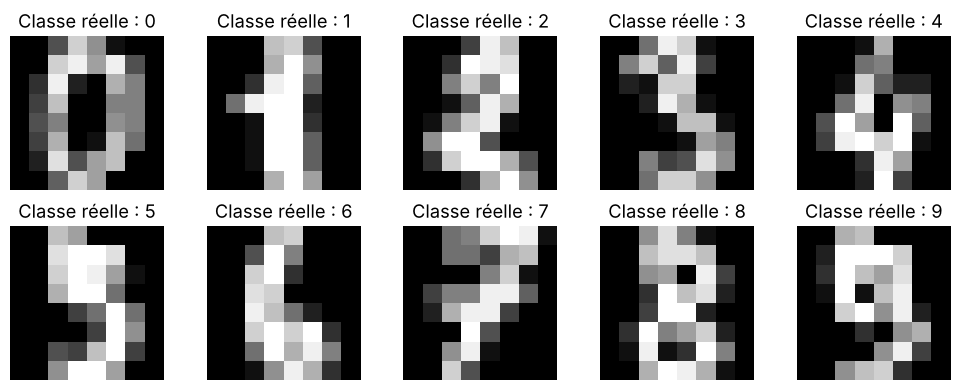

In [3]:
# --- Section 1 : charger et comprendre les données --------------------------
digits = load_digits()
images = digits.images                      # images 8x8 (pour l'affichage)
X = digits.data.astype("float32")           # même données aplaties en 64 variables
y = digits.target.astype("int64")           # classes 0..9
print("X :", X.shape, "y :", y.shape)
print("Classes et effectifs :", np.unique(y, return_counts=True))   # effectifs par chiffre
# Affichage des 10 premières images avec leur classe réelle
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Classe réelle : {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Q1.** Il y a **1797 observations** et **64 variables** (`X.shape = (1797, 64)`). Une ligne de X est **une image 8×8 aplatie** : 64 intensités de pixels entre 0 et 16. C'est une **classification** à 10 classes. Les numéros 0 à 9 sont des **étiquettes** et non des quantités : la classe 7 n'est pas « plus grande » que la classe 3, et se tromper de 1 n'est pas moins grave que de 5, donc une erreur numérique de régression n'a pas de sens.

## 2. Séparer et préparer les données
Garder environ 60 % pour l’entraînement, 20 % pour la validation et 20 % pour le test. La validation servira aux choix du modèle. Le test de digits reste de côté dans cette démonstration. Le travail autonome utilisera un nouveau dataset et son propre test final.

**À COMPLÉTER :** utiliser deux fois `train_test_split` : retirer 20 % pour le test, puis 25 % du reste pour la validation. Ajouter `stratify` et `random_state=SEED`. Ajuster `StandardScaler` seulement sur le train. Utiliser `transform` sur les deux autres ensembles.

**Indice :** `scaler.fit_transform(X_train)` apprend les statistiques et transforme le train. `scaler.transform(X_val)` réutilise ces mêmes statistiques.

**Q2.** Pourquoi conserver les proportions des classes ? Pourquoi ne pas ajuster le scaler sur toutes les images ? Quelle différence entre validation et test ?


In [4]:
# --- Section 2 : séparation et mise à l'échelle -----------------------------
# Étape 1 : 20 % des données sont mises de côté pour le TEST.
# stratify=y conserve la proportion de chaque chiffre dans chaque ensemble.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
# Étape 2 : 25 % du reste (= 20 % du total) pour la VALIDATION ; le reste = TRAIN (60 %).
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev)
# Le scaler apprend moyenne et écart-type sur le TRAIN seulement (évite toute fuite de données).
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # apprend les statistiques ET transforme le train
X_val_s = scaler.transform(X_val)           # réutilise les statistiques du train
X_test_s = scaler.transform(X_test)         # idem pour le test
print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
assert np.allclose(scaler.mean_, X_train.mean(axis=0), atol=1e-5)   # le scaler a bien appris la moyenne du train

Train / validation / test : 1077 360 360


**Q2.** On conserve les proportions des classes (`stratify`) pour que train, validation et test représentent tous les chiffres de façon équilibrée (ici 35 à 37 images par classe en validation). Le scaler n'est pas ajusté sur toutes les images, car moyenne et écart-type de la validation et du test fuiraient dans le prétraitement : ces données doivent rester inconnues à l'entraînement (**fuite de données**). La **validation** sert à comparer et choisir les réglages ; le **test** n'est lu qu'une fois, à la fin, pour estimer la généralisation. Tailles obtenues : 1077 / 360 / 360.

## 3. Définir le MLP avec `Sequential` et `Dense`
Créer un réseau qui reçoit 64 variables, utilise une couche cachée de 32 neurones avec ReLU et produit dix probabilités avec softmax.

- `keras.Sequential` empile les couches dans l’ordre.
- `keras.Input(shape=(64,))` décrit une observation, sans la dimension du lot.
- `Dense(32, activation="relu")` crée 32 neurones entièrement connectés.
- `Dense(10, activation="softmax")` produit une probabilité par classe.
- `summary()` affiche les couches et les paramètres.

**À COMPLÉTER :** construire le modèle puis afficher son résumé. Ne pas créer de classe Python personnalisée.

**Q3.** Combien de couches cachées ? Pourquoi dix sorties ? Combien de paramètres le résumé affiche-t-il ? Relier ce nombre aux poids et biais, sans calculer les gradients.


In [5]:
# --- Section 3 : architecture 64-32-10 avec Sequential et Dense -------------
model = keras.Sequential([
    keras.Input(shape=(64,)),                       # une observation = 64 pixels (sans la dimension du lot)
    layers.Dense(32, activation="relu"),            # couche cachée : 32 neurones, activation ReLU
    layers.Dense(10, activation="softmax"),         # sortie : 10 probabilités (une par chiffre), somme = 1
])
model.summary()                                     # couches, formes de sortie, nombre de paramètres
print("Paramètres :", model.count_params())
# Contrôle : 64*32 + 32 (couche cachée) + 32*10 + 10 (sortie) = 2080 + 330 = 2410
assert model.count_params() == 2410

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,410 (9.41 KB)

 Trainable params: 2,410 (9.41 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 2410


**Q3.** Il y a **une seule couche cachée** (32 neurones, ReLU). Il y a **dix sorties** car il y a dix classes (les chiffres 0 à 9) : softmax donne une probabilité par classe, de somme 1. Le résumé affiche **2410 paramètres** :
- couche cachée : 64×32 poids + 32 biais = 2080 ;
- couche de sortie : 32×10 poids + 10 biais = 330 ;
- total : 2080 + 330 = **2410**.

## 4. Configurer l’apprentissage avec `compile`
`compile` associe au modèle un optimisateur, une perte et des métriques. Ici : Adam, taux 0,001, `SparseCategoricalCrossentropy` et accuracy.

Le mot **sparse** signifie que les cibles sont des indices entiers, par exemple 3, et non des vecteurs one-hot. La sortie du réseau contient déjà softmax : garder `from_logits=False`, valeur par défaut. Ne pas appliquer une seconde sigmoïde ou softmax.

**À COMPLÉTER :** appeler `compile` avec l’optimisateur, la perte et la métrique indiqués.

**Q4.** Quelle différence entre la perte et l’accuracy ? Quelle combinaison sortie/perte utiliser pour une classification binaire ? Pour une régression non contrainte ?


In [6]:
# --- Section 4 : compile (optimisateur, perte, métrique) ----------------------
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # Adam, taux d'apprentissage 0.001
    # "sparse" : les cibles sont des entiers (ex. 3), pas des vecteurs one-hot.
    # from_logits=False : la sortie contient déjà softmax, donc on ne l'applique pas deux fois.
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],                                   # proportion de bonnes classes, suivie à chaque époque
)

**Q4.** La **perte** (entropie croisée) est la quantité différentiable que l'optimisateur minimise : elle tient compte de la confiance des probabilités. L'**accuracy** est la proportion de classes correctement prédites : elle est facile à lire mais non différentiable et ignore la confiance. Pour une **classification binaire** : une sortie sigmoïde et la perte `binary_crossentropy`. Pour une **régression non contrainte** : une sortie linéaire (sans activation) et une perte quadratique (MSE) ou MAE/Huber.

## 5. Entraîner avec `fit`
`fit` lance automatiquement la propagation, le calcul des gradients et la mise à jour des paramètres. Vous choisissez ses arguments, sans écrire ces opérations internes.

**À COMPLÉTER :** entraîner avec 40 époques maximum, lots de 32 et `validation_data=(X_val_s, y_val)`. Utiliser `verbose=0` pour garder le notebook lisible. Ici, pas d’arrêt précoce : toutes les époques demandées seront exécutées.

L’objet retourné est `History`. `history.history` contient notamment `loss`, `accuracy`, `val_loss` et `val_accuracy`.

**Q5.** Que représentent `epochs`, `batch_size` et `validation_data` ? Combien de lots pour 1077 observations avec une taille de 32 ? Les poids s’ajustent-ils à partir de la validation ?


In [7]:
# --- Section 5 : entraînement avec fit ----------------------------------------
# fit enchaîne automatiquement : propagation, perte, gradients, mise à jour des poids.
history = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),   # la validation est seulement MESURÉE, jamais utilisée pour ajuster les poids
    epochs=40,                          # 40 passes complètes sur le train
    batch_size=32,                      # mise à jour des poids tous les 32 exemples
    verbose=0,                          # pas d'affichage ligne par ligne
)
print("Courbes disponibles :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))

Courbes disponibles : ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Époques exécutées : 40


**Q5.** `epochs` est le nombre de passes complètes sur le jeu d'entraînement ; `batch_size` est le nombre d'exemples utilisés pour chaque mise à jour des poids ; `validation_data` fournit des données seulement **mesurées** à chaque fin d'époque. Pour 1077 observations et des lots de 32, il y a ⌈1077/32⌉ = **34 lots** par époque (33 lots de 32 et un dernier de 21). Les poids **ne s'ajustent pas** à partir de la validation : elle ne sert jamais aux gradients.

## 6. Lire les courbes d’apprentissage
Le code d’affichage est fourni. Observer le train et la validation simultanément. Les mesures train de `fit` sont accumulées pendant les mises à jour. La validation est mesurée à la fin de l’époque en mode évaluation : les deux courbes ne proviennent donc pas exactement du même instant.

**Q6.** La perte diminue-t-elle ? Les accuracies progressent-elles ? Un écart train/validation apparaît-il ? Décrire ce que montrent les courbes : une baisse de perte train ne garantit pas une amélioration de validation.


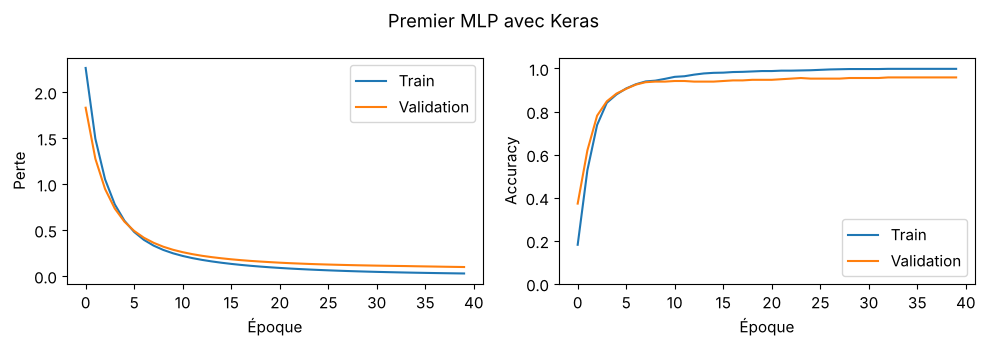

In [8]:
# --- Section 6 : lecture des courbes d'apprentissage (code fourni) -----------
def plot_history(history, title):
    h = history.history                                  # dictionnaire des courbes enregistrées par fit
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")               # perte sur le train
    axes[0].plot(h["val_loss"], label="Validation")      # perte sur la validation
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")           # accuracy train
    axes[1].plot(h["val_accuracy"], label="Validation")  # accuracy validation
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP avec Keras")

**Q6.** La perte **diminue** : train de 2,26 à 0,027 et validation de 1,83 à 0,097 entre l'époque 1 et l'époque 40. Les accuracies **progressent** : train de 0,18 à 0,998 et validation de 0,37 à 0,958. Un **écart train/validation apparaît** : environ 4 points d'accuracy en fin d'entraînement (0,998 contre 0,958) et une perte train très inférieure à la perte de validation, signe que le réseau s'ajuste mieux aux données vues qu'aux nouvelles. Ici la perte de validation est encore à son minimum à l'époque 40, donc il n'y a pas encore de sur-apprentissage net, mais une baisse de perte train ne garantit pas une amélioration de validation : seule la validation renseigne sur la généralisation.

## 7. Prédire et évaluer sur validation
`predict` renvoie ici dix probabilités par image. `np.argmax(..., axis=1)` transforme ces probabilités en classes. `evaluate` renvoie la perte et les métriques configurées lors de `compile`.

**À COMPLÉTER :** prédire sur la validation, obtenir les classes et calculer la matrice de confusion. Utiliser `evaluate(..., return_dict=True)` pour lire les métriques par leur nom.

**Q7.** Quelle forme a le tableau de probabilités ? Pourquoi utiliser argmax plutôt qu’un seuil 0,5 ? Interpréter une confusion, la précision et le rappel d’une classe.


Évaluation : {'accuracy': 0.9583333134651184, 'loss': 0.09728037565946579}
Probabilités : (360, 10)
              precision    recall  f1-score   support

           0      0.973     1.000     0.986        36
           1      0.921     0.946     0.933        37
           2      0.970     0.914     0.941        35
           3      0.949     1.000     0.974        37
           4      0.943     0.917     0.930        36
           5      1.000     0.972     0.986        36
           6      1.000     0.972     0.986        36
           7      0.923     1.000     0.960        36
           8      0.943     0.943     0.943        35
           9      0.971     0.917     0.943        36

    accuracy                          0.958       360
   macro avg      0.959     0.958     0.958       360
weighted avg      0.959     0.958     0.958       360



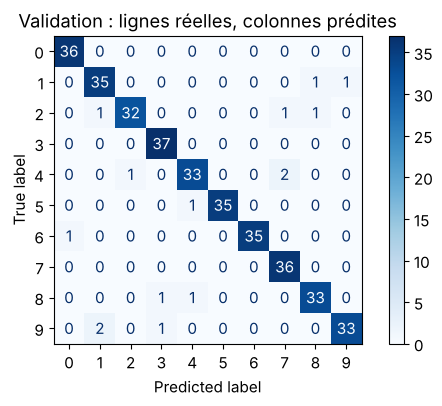

In [9]:
# --- Section 7 : évaluation et prédiction sur la validation ---------------------
# evaluate : renvoie la perte et les métriques de compile, sous forme de dictionnaire nommé
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)
# predict : renvoie 10 probabilités par image, forme (n_images, 10)
prob_val = model.predict(X_val_s, verbose=0)
# argmax : la classe prédite est celle de plus grande probabilité (le seuil 0.5 n'a pas de sens à 10 classes)
pred_val = np.argmax(prob_val, axis=1)
print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)    # softmax : chaque ligne somme à 1
# Rapport par classe : précision, rappel et F1 pour chaque chiffre
print(classification_report(y_val, pred_val, digits=3, zero_division=0))
# Matrice de confusion : lignes = classe réelle, colonnes = classe prédite
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(10))
ConfusionMatrixDisplay(cm_val, display_labels=np.arange(10)).plot(cmap="Blues")
plt.title("Validation : lignes réelles, colonnes prédites")
plt.show()

**Q7.** Le tableau de probabilités a la forme **(360, 10)** : une ligne par image, une colonne par classe. On utilise `argmax` et non un seuil 0,5 car il y a dix classes : plusieurs probabilités peuvent être inférieures à 0,5 ou aucune ne dépasser un seuil ; on prend simplement la classe la plus probable. Sur la validation : accuracy **0,958** et perte **0,097**.

Interprétation : une **confusion** est une image d'une classe prédite dans une autre (par exemple deux « 9 » prédits « 1 », deux « 4 » prédits « 7 »). La **précision** d'une classe est la part de prédictions justes parmi les images prédites dans cette classe (classe 1 : 0,921, soit 35 sur 38 : trois images d'autres chiffres, deux « 9 » et un « 2 », ont été prédites « 1 »). Le **rappel** est la part d'images réelles de la classe retrouvées (classe 9 : 0,917, soit 33 sur 36).

## 8. Comparer des réglages avec des modèles neufs
La fonction fournie ci-dessous assemble uniquement des couches et fonctions Keras. Elle évite de recopier `Sequential` et `compile` pour chaque comparaison. Elle ne calcule ni gradients ni mises à jour manuellement.

La deuxième fonction prépare un résumé de validation. Sans pénalité, `evaluate` renvoie l’entropie croisée. Avec L1/L2, la perte évaluée inclut la pénalité. Pour comparer les variantes sur un critère commun, le résumé calcule aussi une **CE validation sans pénalité** avec la perte Keras prédéfinie.


In [10]:
# --- Section 8 : fonctions utilitaires fournies ---------------------------------
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=64, n_classes=10):
    # Construit et compile un MLP NEUF à chaque appel (mêmes poids initiaux grâce à la graine).
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:                                   # une couche cachée par élément de `hidden`
        net.add(layers.Dense(units, kernel_regularizer=penalty))   # penalty = L1/L2 éventuelle
        if batchnorm:
            net.add(layers.BatchNormalization())           # normalise les activations du lot
        net.add(layers.Activation(activation))             # activation après (éventuelle) normalisation
        if dropout > 0:
            net.add(layers.Dropout(dropout))               # masque aléatoire, actif seulement à l'entraînement
    net.add(layers.Dense(n_classes, activation="softmax")) # sortie : une probabilité par classe
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))  # choix de l'optimisateur
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

# Entropie croisée "pure" (sans pénalité L1/L2) pour comparer les modèles sur un critère commun
validation_loss = keras.losses.SparseCategoricalCrossentropy()
def summarize(name, net, hist):
    # Résume un modèle sur la VALIDATION : paramètres, époques, CE, accuracy, F1 macro
    # Attention : la CE est recalculée ici à partir des PROBABILITÉS renvoyées par predict.
    # Keras tronque ces probabilités à 1e-7 : une erreur très confiante (p ~ 1e-25 pour la vraie
    # classe) est donc sous-estimée. `evaluate` calcule la perte à partir des logits (avant softmax)
    # et la mesure exactement ; c'est ce qui explique l'écart observé pour BatchNorm (0.181 ici,
    # contre 0.297 avec evaluate). Pour les autres modèles les deux valeurs coïncident.
    proba = net.predict(X_val_s, verbose=0)
    pred = proba.argmax(axis=1)
    return {"modèle": name, "paramètres": net.count_params(),
            "époques": len(hist.history["loss"]),
            "CE_validation": float(validation_loss(y_val, proba).numpy()),
            "accuracy_validation": accuracy_score(y_val, pred),
            "F1_macro_validation": f1_score(y_val, pred, average="macro")}

### Taux d’apprentissage
**À COMPLÉTER :** avec `create_model(rate=eta)`, entraîner un réseau neuf pour chaque taux 0,0001, 0,001 et 0,05. Garder 30 époques et des lots de 32. Stocker le modèle et son historique dans `rate_runs`.

**Q8.** Quel taux avance lentement ? Le grand taux est-il instable dans cette expérience ? Expliquer à partir des courbes et des scores, sans supposer qu’un grand taux diverge toujours.


{'modèle': 'Adam, taux=0.0001', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.954008936882019, 'accuracy_validation': 0.7777777777777778, 'F1_macro_validation': 0.7540358876957709}


{'modèle': 'Adam, taux=0.001', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.11437371373176575, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554220401078168}


{'modèle': 'Adam, taux=0.05', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.35169902443885803, 'accuracy_validation': 0.9722222222222222, 'F1_macro_validation': 0.9721046321657024}


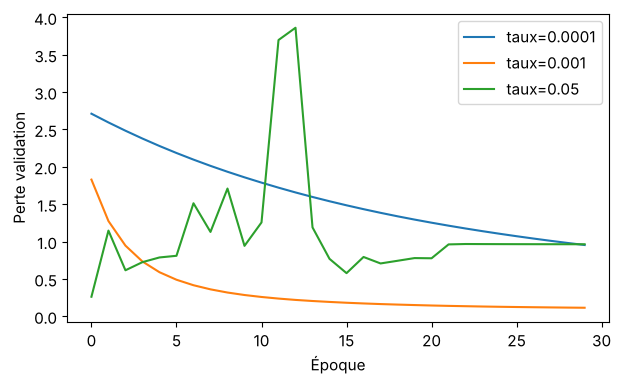

In [11]:
# --- Comparaison de trois taux d'apprentissage -----------------------------------
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:
    # Un réseau NEUF pour chaque taux, pour que la comparaison soit équitable.
    net = create_model(rate=eta)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)                      # on garde le modèle et son historique
    print(summarize(f"Adam, taux={eta}", net, hist))
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")   # courbe de la perte de validation
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
plt.show()

**Q8.** Le taux **0,0001** avance lentement : après 30 époques l'accuracy de validation n'est que de 0,778 et la CE de 0,954. Le grand taux **0,05** n'est **pas instable** ici : sa courbe ne diverge pas et son accuracy (0,972) est même la plus élevée. En revanche sa CE de validation (0,352) est plus mauvaise que celle de 0,001 (0,114) : il prédit juste mais avec des erreurs plus confiantes et une courbe plus irrégulière. Le taux **0,001** donne la meilleure CE (0,114). Il ne faut donc pas supposer qu'un grand taux diverge toujours ; cela dépend de l'optimisateur et du problème, et le meilleur choix dépend du critère (CE ou accuracy).

### Optimisateurs Adam et SGD
Le code fourni compare Adam et SGD sans momentum avec le même taux 0,001. Cette comparaison montre comment remplacer un optimisateur. Un même taux n’est pas forcément adapté aux deux algorithmes.

**Q9.** Quel appel Keras change ? Peut-on conclure qu’un optimisateur est toujours meilleur à partir de ce seul essai ? Quel paramètre faudrait-il aussi régler pour une comparaison plus pertinente ?


In [12]:
# --- Optimisateurs : Adam contre SGD (même taux 0.001) -------------------------
optimizer_runs = {}
for opt in ["adam", "sgd"]:
    net = create_model(rate=0.001, optimizer=opt)     # seul l'argument `optimizer` change
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

{'modèle': 'adam', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.11437371373176575, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554220401078168}


{'modèle': 'sgd', 'paramètres': 2410, 'époques': 30, 'CE_validation': 1.538389801979065, 'accuracy_validation': 0.5194444444444445, 'F1_macro_validation': 0.4897808509222372}


**Q9.** Le changement porte sur l'objet passé à `compile(optimizer=...)` : `keras.optimizers.Adam(learning_rate=...)` contre `keras.optimizers.SGD(learning_rate=...)`. Avec le même taux 0,001, Adam atteint 0,956 d'accuracy et SGD seulement 0,519 après 30 époques. On **ne peut pas** conclure qu'Adam est toujours meilleur à partir de ce seul essai : un même taux n'est pas adapté aux deux algorithmes, et il n'y a qu'une exécution. Pour une comparaison plus pertinente il faudrait **régler le taux d'apprentissage de chaque optimisateur** (et le momentum de SGD), éventuellement avec plusieurs graines.

### Tailles des lots
Le code fourni compare un exemple, un mini-lot de 32 et un lot complet. Le modèle utilise SGD avec un taux 0,01. Garder dix époques pour chaque essai.

**Q10.** Combien de mises à jour par époque pour les trois cas ? Pourquoi le même nombre d’époques ne signifie-t-il pas le même nombre de mises à jour ?


In [13]:
# --- Tailles de lots : 1 exemple, mini-lot de 32, lot complet ---------------------
batch_runs = {}
for size in [1, 32, len(y_train)]:
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    # Nombre de mises à jour des poids par époque = nombre de lots = ceil(n / taille du lot)
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

{'modèle': 'SGD, lot=1', 'paramètres': 2410, 'époques': 10, 'CE_validation': 0.13488081097602844, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554015485522005}
Mises à jour par époque : 1077


{'modèle': 'SGD, lot=32', 'paramètres': 2410, 'époques': 10, 'CE_validation': 0.7272274494171143, 'accuracy_validation': 0.8416666666666667, 'F1_macro_validation': 0.8337544345352566}
Mises à jour par époque : 34


{'modèle': 'SGD, lot=1077', 'paramètres': 2410, 'époques': 10, 'CE_validation': 2.621835231781006, 'accuracy_validation': 0.075, 'F1_macro_validation': 0.057104461921766006}
Mises à jour par époque : 1


**Q10.** Mises à jour par époque : **1077** (lot de 1), **34** (lot de 32) et **1** (lot complet). Sur 10 époques cela fait 10 770, 340 et 10 mises à jour. Le nombre d'époques est un nombre de passes sur les données, pas de mises à jour : avec un lot complet, 10 époques n'apportent que 10 mises à jour, ce qui explique que ce réseau n'ait presque pas appris (accuracy 0,075, proche du hasard à 0,10), alors que le lot de 1 atteint 0,956 et le lot de 32 0,842.

### Couches cachées et activations
Le code fourni compare un réseau étroit, une référence, un réseau à deux couches cachées et une activation tanh. Les sorties restent softmax.

**Q11.** Repérer les changements de couches dans les configurations. Comparer les paramètres et les scores de validation. Un plus grand réseau améliore-t-il toujours la généralisation ?


In [14]:
# --- Couches cachées et activations ------------------------------------------------
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"),             # 1 couche de 2 neurones : goulot d'étranglement
        ("référence", (32,), "relu"),         # 1 couche de 32 neurones
        ("deux couches", (64, 32), "relu"),   # 2 couches cachées
        ("tanh", (32,), "tanh")]:             # même taille, autre activation
    net = create_model(hidden=hidden, activation=activation)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))

{'modèle': 'étroit', 'paramètres': 160, 'époques': 30, 'CE_validation': 1.4542880058288574, 'accuracy_validation': 0.43333333333333335, 'F1_macro_validation': 0.3539566226076078}


{'modèle': 'référence', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.11437371373176575, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554220401078168}


{'modèle': 'deux couches', 'paramètres': 6570, 'époques': 30, 'CE_validation': 0.12433215975761414, 'accuracy_validation': 0.975, 'F1_macro_validation': 0.9749278002233932}


{'modèle': 'tanh', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.1368870586156845, 'accuracy_validation': 0.9638888888888889, 'F1_macro_validation': 0.9637685881370093}


**Q11.** Les changements portent sur `hidden` (largeur et nombre de couches) et `activation`. Paramètres et scores de validation : **étroit** (2 neurones) 160 paramètres, accuracy 0,433 ; **référence** (32) 2410, accuracy 0,956, CE 0,114 ; **deux couches** (64, 32) 6570, accuracy 0,975 mais CE 0,124 ; **tanh** 2410, accuracy 0,964, CE 0,137. Le réseau étroit sous-apprend (goulot de 2 neurones). Un plus grand réseau **n'améliore pas toujours** la généralisation : le réseau à deux couches gagne un peu en accuracy mais sa CE est moins bonne que celle de la référence, et les différences sur 360 images sont petites.

## 9. Régulariser avec les couches et objets Keras
Les opérations prédéfinies évitent d’écrire les mécanismes internes :

- `keras.regularizers.l1(0.0001)` pénalise les poids via L1.
- `keras.regularizers.l2(0.001)` pénalise les poids via L2.
- `layers.Dropout(0.25)` masque aléatoirement une partie des activations pendant l’entraînement.
- `layers.BatchNormalization()` transforme les activations avec les statistiques du lot pendant l’entraînement, puis avec ses statistiques mobiles en évaluation.

Le code fourni active une seule option à la fois dans un MLP à deux couches cachées. Le même StandardScaler reste appliqué aux entrées. BatchNorm intervient à l’intérieur du réseau et ne remplace pas ce scaler.

**Q12.** Comparer les CE de validation sans pénalité. Pourquoi `evaluate` peut-il afficher une autre perte avec L1/L2 ? Quand Dropout est-il actif ? Pourquoi appeler `predict` ou `evaluate` pour une prédiction finale ? Une option améliore-t-elle systématiquement les résultats ?


{'modèle': 'référence', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.12130666524171829, 'accuracy_validation': 0.9777777777777777, 'F1_macro_validation': 0.9777865968387015}
Perte evaluate, pénalité éventuelle incluse : 0.12130648642778397


{'modèle': 'L1', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.08352840691804886, 'accuracy_validation': 0.9777777777777777, 'F1_macro_validation': 0.9777860608985552}
Perte evaluate, pénalité éventuelle incluse : 0.15148986876010895


{'modèle': 'L2', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.07869719713926315, 'accuracy_validation': 0.975, 'F1_macro_validation': 0.9748760506468196}
Perte evaluate, pénalité éventuelle incluse : 0.16675075888633728


{'modèle': 'Dropout', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.13026849925518036, 'accuracy_validation': 0.9638888888888889, 'F1_macro_validation': 0.9637168935530877}
Perte evaluate, pénalité éventuelle incluse : 0.13026830554008484


{'modèle': 'BatchNorm', 'paramètres': 6954, 'époques': 35, 'CE_validation': 0.181334987282753, 'accuracy_validation': 0.9527777777777777, 'F1_macro_validation': 0.952746465373379}
Perte evaluate, pénalité éventuelle incluse : 0.2967980206012726


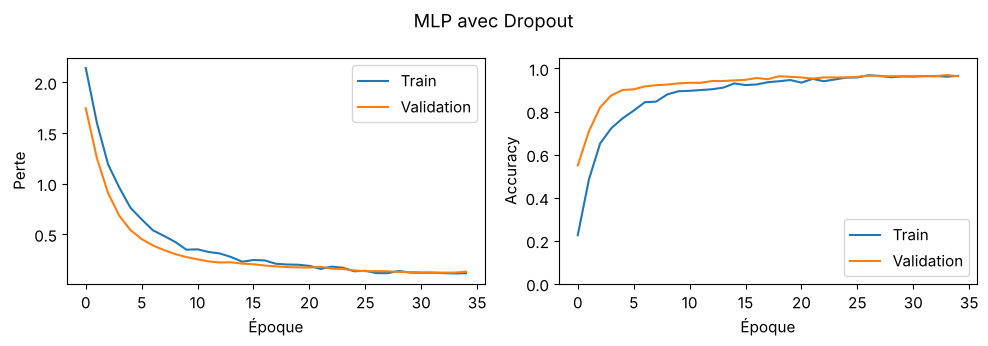

In [15]:
# --- Section 9 : régularisation (une option à la fois, réseau 64-32) ----------------
regularization_runs = {}
configs = [
    ("référence", {}),                                          # aucune régularisation
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),         # pénalise la somme des |poids|
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),          # pénalise la somme des poids au carré
    ("Dropout", {"dropout": 0.25}),                             # éteint 25 % des neurones à l'entraînement
    ("BatchNorm", {"batchnorm": True})                          # normalise les activations du lot
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))
    # evaluate inclut la pénalité L1/L2 dans la perte : elle peut donc dépasser la CE pure ci-dessus
    print("Perte evaluate, pénalité éventuelle incluse :",
          net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
plot_history(regularization_runs["Dropout"][1], "MLP avec Dropout")

In [16]:
# Diagnostic fourni : aucun calcul de gradient.
# Vérifie quand Dropout est actif : training=False -> désactivé, training=True -> actif.
probe = keras.Sequential([
    keras.Input(shape=(64,)), layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), layers.Dense(10, activation="softmax")
])
eval1 = probe(X_val_s[:8], training=False).numpy()    # mode évaluation, 1er appel
eval2 = probe(X_val_s[:8], training=False).numpy()    # mode évaluation, 2e appel
train1 = probe(X_val_s[:8], training=True).numpy()    # mode entraînement, 1er appel
train2 = probe(X_val_s[:8], training=True).numpy()    # mode entraînement, 2e appel (masque différent)
print("Évaluation identique :", np.allclose(eval1, eval2))        # attendu : True
print("Entraînement identique :", np.allclose(train1, train2))    # attendu : False

Évaluation identique : True
Entraînement identique : False


**Q12.** CE de validation **sans pénalité** (réseau 64-32) : référence 0,121 ; L1 0,084 ; L2 0,079 ; Dropout 0,130 ; BatchNorm 0,181 (voir la remarque ci-dessous). `evaluate` peut afficher une autre perte avec L1/L2 car la perte évaluée **inclut la pénalité** sur les poids : 0,151 pour L1 (0,084 + 0,068) et 0,167 pour L2 (0,079 + 0,088). **Dropout n'est actif qu'à l'entraînement** (`training=True`) : le diagnostic ci-dessus le montre, deux appels en évaluation donnent la même sortie (`True`), deux appels en entraînement des sorties différentes (`False`). Il faut donc appeler `predict` ou `evaluate` pour une prédiction finale, qui désactivent Dropout et utilisent les statistiques mobiles de BatchNorm. Aucune option n'améliore **systématiquement** les résultats : ici L1 et L2 baissent la CE sans changer l'accuracy (0,978 et 0,975 contre 0,978), Dropout et BatchNorm la dégradent, sur une seule graine et 360 images.

*Remarque sur BatchNorm :* la CE calculée par `summarize` (0,181) est **sous-estimée**. Elle est recalculée à partir des probabilités tronquées à 1e-7, et un exemple a une probabilité d'environ 9·10⁻²⁶ pour sa vraie classe. `evaluate`, qui travaille à partir des logits, donne 0,297, valeur exacte (je l'ai vérifiée en la recalculant depuis les logits : 0,296). Avec cette valeur exacte, BatchNorm est nettement la pire option. Pour les autres modèles, les deux calculs coïncident.

## 10. Arrêt précoce avec `EarlyStopping`
Keras peut arrêter l’apprentissage lorsque la perte de validation ne s’améliore plus. `patience=8` autorise huit époques sans amélioration. `restore_best_weights=True` restaure les meilleurs poids selon la perte suivie. Ici, `min_delta=0` rend le critère directement comparable au minimum de la courbe.

**À COMPLÉTER :** créer le callback, construire un réseau neuf, puis entraîner au maximum 100 époques en ajoutant `callbacks=[early_stop]` dans `fit`.

**Q13.** Combien d’époques ont été exécutées ? À quelle époque se situe la plus faible perte de validation ? Pourquoi ces nombres peuvent-ils différer ? L’arrêt est-il garanti avant le maximum ?


Époques exécutées : 100
Meilleure époque : 100
{'accuracy': 0.9750000238418579, 'loss': 0.0609213188290596}


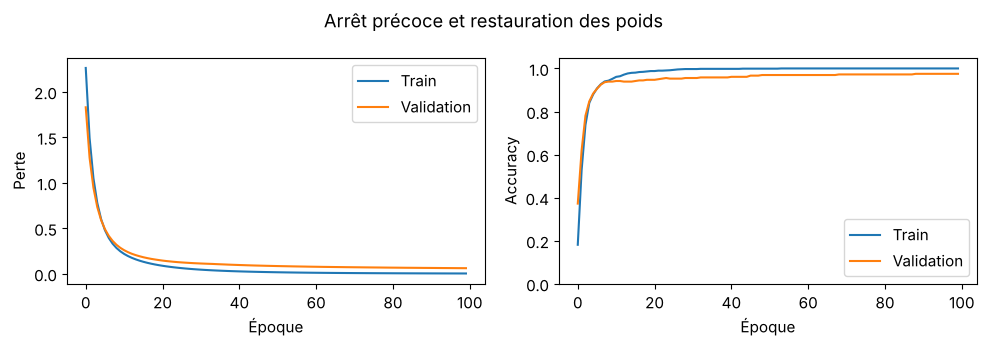

In [17]:
# --- Section 10 : arrêt précoce avec EarlyStopping ---------------------------------
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",           # on surveille la perte de validation
    patience=8,                   # on tolère 8 époques sans amélioration
    min_delta=0,                  # toute amélioration, même minime, compte
    restore_best_weights=True,    # on revient aux poids de la meilleure époque
)
early_model = create_model()      # réseau neuf (64-32-10, Adam 0.001)
early_history = early_model.fit(
    X_train_s, y_train, validation_data=(X_val_s, y_val),
    epochs=100, batch_size=32, verbose=0,    # 100 époques MAXIMUM : l'arrêt peut survenir avant
    callbacks=[early_stop],
)
print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))   # +1 : les époques sont numérotées depuis 1
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))
plot_history(early_history, "Arrêt précoce et restauration des poids")

**Q13.** **100 époques** ont été exécutées, et la plus faible perte de validation est à l'**époque 100** (0,0609) : l'arrêt précoce **ne s'est pas déclenché**. La perte de validation a continué à baisser très lentement jusqu'à la fin (0,0853 à l'époque 50, 0,0609 à l'époque 100), donc aucune série de 8 époques sans amélioration n'est apparue (la plus longue série est de 0 époque). Quand l'arrêt se déclenche, le nombre d'époques exécutées est supérieur à la meilleure époque d'environ `patience` (ici 8), d'où des nombres différents ; avec `restore_best_weights=True` on récupère les poids de la meilleure époque. L'arrêt n'est **pas garanti** avant le maximum : si la validation s'améliore encore, l'entraînement va jusqu'à `epochs`. Ici le maximum de 100 époques est le véritable critère d'arrêt (accuracy de validation 0,975).

## 11. Sauvegarder et recharger le modèle
Cette manipulation illustre le passage d’une expérience à un composant d’application. Le format `.keras` conserve le modèle et ses poids. **Il ne conserve pas le StandardScaler de scikit-learn.** Une application devra sauvegarder aussi ce prétraitement et le réutiliser, jamais le réajuster sur chaque nouvelle entrée.

**À COMPLÉTER :** sauvegarder `early_model` avec `save("modele_mlp.keras")`, puis le recharger avec `keras.models.load_model`. Comparer les probabilités sur cinq images de validation déjà standardisées.

**Q14.** Pourquoi la sauvegarde du réseau seule ne suffit-elle pas pour servir des images brutes ? Quelle transformation appliquer avant predict ? En quoi predict diffère-t-il de fit ?


In [18]:
# --- Section 11 : sauvegarder puis recharger le modèle ----------------------------
early_model.save("modele_mlp.keras")                          # architecture + poids (PAS le StandardScaler)
loaded_model = keras.models.load_model("modele_mlp.keras")    # reconstruction à l'identique
# Les prédictions doivent être les mêmes avant et après sauvegarde (5 images de validation déjà standardisées)
p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))
assert np.allclose(p_before, p_after, atol=1e-6)

Prédictions conservées : True


**Q14.** Le fichier `.keras` ne contient que l'architecture et les poids, **pas le `StandardScaler`**. Or le réseau a été entraîné sur des entrées standardisées : lui donner des images brutes (intensités de 0 à 16) lui présenterait des valeurs d'une autre échelle et fausserait les prédictions. Avant `predict` il faut appliquer `scaler.transform(...)`, avec le scaler **ajusté sur le train** (sauvegardé à part, par exemple avec `joblib`), sans jamais le réajuster sur les nouvelles images. `predict` diffère de `fit` : il fait seulement la propagation avant en mode inférence et renvoie des probabilités ; il n'utilise pas de cibles, ne calcule aucun gradient et ne modifie pas les poids, alors que `fit` met les poids à jour.

## Documentation utile

- [Sequential et couches Dense](https://keras.io/guides/sequential_model/)
- [compile, fit, evaluate et predict](https://keras.io/guides/training_with_built_in_methods/)
- [EarlyStopping](https://keras.io/api/callbacks/early_stopping/)
- [Dropout](https://keras.io/api/layers/regularization_layers/dropout/)
- [BatchNormalization](https://keras.io/api/layers/normalization_layers/batch_normalization/)

Pour rendre le notebook reproductible, utiliser les mêmes ensembles et des modèles neufs pour chaque configuration. Des versions ou matériels différents peuvent produire des résultats légèrement différents malgré le seed.


# Suite du TP — Dataset Dry Bean

Cette partie reprend les étapes 1 à 11 et les questions Q1 à Q14 de Digits. Elle remplace le travail autonome Wine Quality par Dry Bean, conformément à la nouvelle consigne. Les résultats Digits ci-dessus sont conservés.

Source : [Dry Bean, UCI (2020)](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset), DOI 10.24432/C50S4B, licence CC BY 4.0. Les entrées sont des mesures extraites des grains, et non les photographies brutes.

Exécuter cette partie dans l’ordre. Les scores et commentaires numériques sont calculés par les cellules ; aucun score Digits n’est réutilisé. Les imports et fonctions sont redéfinis pour permettre de lancer cette partie avec un kernel neuf. La comparaison des lots de taille 1 peut prendre plusieurs minutes.

**État de vérification :** syntaxe des cellules Python vérifiée. Les cellules Dry Bean sont complétées mais leurs entraînements n’ont pas été exécutés dans cet environnement ; leurs sorties seront générées dans Jupyter ou Colab. Les sorties Digits proviennent du notebook fourni.


## Installation et imports
La commande demandée installe ucimlrepo dans le kernel courant. Si les autres imports manquent : %pip install tensorflow scikit-learn pandas matplotlib joblib.

In [ ]:
%pip install -q ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.dummy import DummyClassifier
from IPython.display import display, Markdown
import joblib
import json
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})
print("TensorFlow :", tf.__version__)


## 1. Charger et comprendre les données
**Q1.** Quelles sont les dimensions, les variables et les classes ? Pourquoi s’agit-il d’une classification ?

In [ ]:
from ucimlrepo import fetch_ucirepo

dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features
y = dry_bean.data.targets.values.ravel()

print(X.shape)
print(y.shape)
X_raw = X.copy()
y_raw = y.copy()
display(X.head(10))
display(X.dtypes.to_frame("type"))
display(X.describe().T)
print("Valeurs manquantes dans X :", X.isna().sum().sum())
print("Valeurs manquantes dans y :", pd.isna(y).sum())
counts = pd.Series(y, name="classe").value_counts().sort_index()
display(counts.to_frame("effectif"))
counts.plot.bar(rot=40, ylabel="Effectif", title="Dry Bean : répartition des classes")
plt.tight_layout()
plt.show()
X.hist(figsize=(14, 10), bins=30)
plt.suptitle("Distribution des 16 mesures")
plt.tight_layout()
plt.show()

# Retirer les lignes entièrement identiques avant le découpage.
beans = X.copy()
beans["Class"] = y
print("Doublons exacts (entrées + cible) :", beans.duplicated().sum())
beans = beans.drop_duplicates().reset_index(drop=True)
X = beans.drop(columns="Class")
y_labels = beans["Class"].to_numpy()
assert not X.isna().any().any() and not pd.isna(y_labels).any()
assert np.isfinite(X.to_numpy()).all()
print("Dimensions après dédoublonnage :", X.shape)
display(Markdown(f"**Réponse Q1.** Le chargement contient **{X_raw.shape[0]} observations** et **{X_raw.shape[1]} variables**. Une ligne décrit un grain par ses mesures de taille et de forme. La cible indique sa variété : c’est une **classification multiclasse**, avec **{len(counts)} classes nominales**, sans ordre numérique. Les graphiques représentent les mesures, car les photos ne sont pas fournies par ce chargement."))


## 2. Séparer et préparer les données
Découpage stratifié 60/20/20. Un nouveau StandardScaler apprend exclusivement sur le train. Les noms des variétés doivent être encodés en indices entiers pour la perte sparse.

In [ ]:
X_dev, X_test, labels_dev, labels_test = train_test_split(
    X, y_labels, test_size=0.20, random_state=SEED, stratify=y_labels)
X_train, X_val, labels_train, labels_val = train_test_split(
    X_dev, labels_dev, test_size=0.25, random_state=SEED, stratify=labels_dev)
encoder = LabelEncoder()
y_train = encoder.fit_transform(labels_train)
y_val = encoder.transform(labels_val)
y_test = encoder.transform(labels_test)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype("float32")
X_val_s = scaler.transform(X_val).astype("float32")
X_test_s = scaler.transform(X_test).astype("float32")
input_dim = X_train_s.shape[1]
n_classes = len(encoder.classes_)
print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
display(pd.DataFrame({"indice": np.arange(n_classes), "variété": encoder.classes_}))
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert np.allclose(scaler.mean_, X_train.mean(axis=0))


**Q2.** La stratification conserve les proportions des variétés, y compris les moins représentées. Le scaler apprend moyenne et écart-type sur le train uniquement afin d’éviter une fuite de données. La validation sert à choisir les réglages ; le test est réservé à l’évaluation finale. Le LabelEncoder mémorise la correspondance entre noms de variétés et indices 0 à 6.

## 3. Définir le MLP avec Sequential et Dense
Architecture de départ : 16 entrées, 32 neurones ReLU, 7 sorties softmax.

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(input_dim,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
model.summary()
expected_params = (input_dim + 1) * 32 + (32 + 1) * n_classes
assert model.count_params() == expected_params
print("Paramètres :", model.count_params())


**Q3.** Une couche cachée de 32 neurones. Les sept sorties correspondent aux sept variétés. Paramètres : (16 × 32 + 32) + (32 × 7 + 7) = **775**. Softmax produit une distribution de probabilités de somme 1.

## 4. Configurer l’apprentissage avec compile

In [ ]:
# --- Section 4 : compile (optimisateur, perte, métrique) ----------------------
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # Adam, taux d'apprentissage 0.001
    # "sparse" : les cibles sont des entiers (ex. 3), pas des vecteurs one-hot.
    # from_logits=False : la sortie contient déjà softmax, donc on ne l'applique pas deux fois.
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],                                   # proportion de bonnes classes, suivie à chaque époque
)

**Q4.** La perte sparse_categorical_crossentropy mesure la qualité des probabilités et sert à entraîner le réseau ; l’accuracy mesure la proportion de bonnes classes. Les cibles sont des indices entiers. La sortie contient déjà softmax, donc from_logits=False. En binaire : sigmoïde et binary_crossentropy ; en régression non contrainte : sortie linéaire et MSE, par exemple.

## 5. Entraîner avec fit
Même protocole que Digits : 40 époques, lots de 32, validation explicite.

In [ ]:
# --- Section 5 : entraînement avec fit ----------------------------------------
# fit enchaîne automatiquement : propagation, perte, gradients, mise à jour des poids.
history = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),   # la validation est seulement MESURÉE, jamais utilisée pour ajuster les poids
    epochs=40,                          # 40 passes complètes sur le train
    batch_size=32,                      # mise à jour des poids tous les 32 exemples
    verbose=0,                          # pas d'affichage ligne par ligne
)
print("Courbes disponibles :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))

In [ ]:
print("Lots par époque :", int(np.ceil(len(y_train) / 32)))
print("Dernier lot :", (len(y_train) - 1) % 32 + 1)


**Q5.** Une époque est une passe sur le train ; batch_size est le nombre d’exemples par mise à jour. Le nombre de lots est ceil(n_train/32). La validation est mesurée à la fin de chaque époque ; elle n’intervient pas dans le calcul des gradients.

## 6. Lire les courbes d’apprentissage

In [ ]:
# --- Section 6 : lecture des courbes d'apprentissage (code fourni) -----------
def plot_history(history, title):
    h = history.history                                  # dictionnaire des courbes enregistrées par fit
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")               # perte sur le train
    axes[0].plot(h["val_loss"], label="Validation")      # perte sur la validation
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")           # accuracy train
    axes[1].plot(h["val_accuracy"], label="Validation")  # accuracy validation
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP — Dry Bean")

In [ ]:
h = history.history
display(pd.DataFrame({
    "mesure": ["perte train", "perte validation", "accuracy train", "accuracy validation"],
    "début": [h[k][0] for k in ("loss", "val_loss", "accuracy", "val_accuracy")],
    "fin": [h[k][-1] for k in ("loss", "val_loss", "accuracy", "val_accuracy")]
}))
print("Minimum de perte validation : époque", 1 + np.argmin(h["val_loss"]))
print("Écart accuracy train - validation en fin :", h["accuracy"][-1] - h["val_accuracy"][-1])


**Q6.** Le tableau et les courbes permettent de vérifier la baisse de perte et la progression des accuracies. Une perte train qui baisse tandis que la perte validation remonte signale un surapprentissage. Un écart seul ne prouve pas que la validation se dégrade. Les mesures train sont accumulées pendant les mises à jour ; celles de validation utilisent les poids de fin d’époque.

## 7. Prédire et évaluer sur validation

In [ ]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)
prob_val = model.predict(X_val_s, verbose=0)
pred_val = prob_val.argmax(axis=1)
print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)
print(classification_report(y_val, pred_val, labels=np.arange(n_classes),
                            target_names=encoder.classes_, digits=3, zero_division=0))
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(n_classes))
ConfusionMatrixDisplay(cm_val, display_labels=encoder.classes_).plot(
    cmap="Blues", xticks_rotation=45)
plt.title("Dry Bean — validation")
plt.tight_layout()
plt.show()
errors = cm_val.copy()
np.fill_diagonal(errors, 0)
if errors.max() > 0:
    a, b = np.unravel_index(errors.argmax(), errors.shape)
    print("Confusion la plus fréquente :", encoder.classes_[a], "prédit",
          encoder.classes_[b], ":", errors[a, b], "observations")


**Q7.** Les probabilités ont la forme (n_validation, 7). argmax choisit la variété la plus probable, même si sa probabilité est inférieure à 0,5. Les lignes de la matrice sont les variétés réelles et les colonnes les prédictions. La précision mesure la fiabilité des prédictions d’une classe ; le rappel mesure la proportion des grains réels de cette classe retrouvés.

## 8. Comparer des réglages avec des modèles neufs
Les mêmes découpages et le même scaler sont utilisés. Chaque appel crée des poids neufs avec SEED=42. La CE sans pénalité est calculée depuis les logits pour éviter la troncature des probabilités très faibles.

In [ ]:
# --- Section 8 : fonctions utilitaires fournies ---------------------------------
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=input_dim, n_classes=n_classes):
    # Construit et compile un MLP NEUF à chaque appel (mêmes poids initiaux grâce à la graine).
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:                                   # une couche cachée par élément de `hidden`
        net.add(layers.Dense(units, kernel_regularizer=penalty))   # penalty = L1/L2 éventuelle
        if batchnorm:
            net.add(layers.BatchNormalization())           # normalise les activations du lot
        net.add(layers.Activation(activation))             # activation après (éventuelle) normalisation
        if dropout > 0:
            net.add(layers.Dropout(dropout))               # masque aléatoire, actif seulement à l'entraînement
    net.add(layers.Dense(n_classes, activation="softmax")) # sortie : une probabilité par classe
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))  # choix de l'optimisateur
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net


# CE stable depuis les logits de la dernière couche Dense.
# Fonction adaptée uniquement aux modèles créés ici (sortie Dense softmax).
def pure_ce(net, data, targets):
    feature_net = keras.Model(inputs=net.inputs, outputs=net.layers[-2].output)
    features = feature_net.predict(data, verbose=0)
    output = net.layers[-1]
    logits = tf.linalg.matmul(features, output.kernel) + output.bias
    return float(keras.losses.SparseCategoricalCrossentropy(from_logits=True)(
        targets, logits).numpy())

def summarize(name, net, hist):
    pred = net.predict(X_val_s, verbose=0).argmax(axis=1)
    row = {"modèle": name, "paramètres": net.count_params(),
           "époques": len(hist.history["loss"]),
           "CE_validation": pure_ce(net, X_val_s, y_val),
           "accuracy_validation": accuracy_score(y_val, pred),
           "F1_macro_validation": f1_score(y_val, pred, average="macro")}
    recalls = recall_score(y_val, pred, labels=np.arange(n_classes),
                           average=None, zero_division=0)
    row.update({f"rappel_{label}": float(score)
                for label, score in zip(encoder.classes_, recalls)})
    return row


### Taux d’apprentissage
Trois taux Adam : 0,0001 ; 0,001 ; 0,05. 30 époques, lots de 32.

In [ ]:
# --- Comparaison de trois taux d'apprentissage -----------------------------------
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:
    # Un réseau NEUF pour chaque taux, pour que la comparaison soit équitable.
    net = create_model(rate=eta)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)                      # on garde le modèle et son historique
    print(summarize(f"Adam, taux={eta}", net, hist))
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")   # courbe de la perte de validation
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
plt.show()

**Q8.** Un petit taux ralentit les mises à jour. Un grand taux peut produire une courbe irrégulière, mais ne diverge pas nécessairement. On compare ici les courbes et les CE mesurées ; les scores Digits ne permettent pas de conclure pour Dry Bean.

### Optimisateurs Adam et SGD
Même taux 0,001, 30 époques et lots de 32.

In [ ]:
# --- Optimisateurs : Adam contre SGD (même taux 0.001) -------------------------
optimizer_runs = {}
for opt in ["adam", "sgd"]:
    net = create_model(rate=0.001, optimizer=opt)     # seul l'argument `optimizer` change
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

**Q9.** L’objet optimizer passé à compile change. Un seul taux commun ne permet pas de déclarer un optimisateur toujours meilleur : il faudrait régler le taux de chacun et éventuellement le momentum de SGD.

### Tailles des lots
SGD au taux 0,01, 10 époques : un exemple, 32 exemples et train complet.

In [ ]:
# --- Tailles de lots : 1 exemple, mini-lot de 32, lot complet ---------------------
batch_runs = {}
for size in [1, 32, len(y_train)]:
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    # Nombre de mises à jour des poids par époque = nombre de lots = ceil(n / taille du lot)
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

**Q10.** Les nombres de mises à jour par époque sont n_train, ceil(n_train/32) et 1. Un même nombre d’époques ne représente donc pas le même nombre de mises à jour. Les effectifs exacts sont affichés ci-dessus.

### Couches cachées et activations
Étroit (2), référence (32), deux couches (64, 32), et tanh (32).

In [ ]:
# --- Couches cachées et activations ------------------------------------------------
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"),             # 1 couche de 2 neurones : goulot d'étranglement
        ("référence", (32,), "relu"),         # 1 couche de 32 neurones
        ("deux couches", (64, 32), "relu"),   # 2 couches cachées
        ("tanh", (32,), "tanh")]:             # même taille, autre activation
    net = create_model(hidden=hidden, activation=activation)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))

**Q11.** hidden change la largeur ou le nombre de couches ; activation change ReLU en tanh. Un réseau plus grand a davantage de paramètres, sans garantie d’améliorer la validation. Les tableaux affichent les paramètres, l’accuracy et la CE obtenus.

## 9. Régulariser avec les couches et objets Keras
Réseau à couches cachées (64, 32) ; une option à la fois : L1, L2, Dropout ou BatchNorm. 35 époques et lots de 32.

In [ ]:
# --- Section 9 : régularisation (une option à la fois, réseau 64-32) ----------------
regularization_runs = {}
configs = [
    ("référence", {}),                                          # aucune régularisation
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),         # pénalise la somme des |poids|
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),          # pénalise la somme des poids au carré
    ("Dropout", {"dropout": 0.25}),                             # éteint 25 % des neurones à l'entraînement
    ("BatchNorm", {"batchnorm": True})                          # normalise les activations du lot
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))
    # evaluate inclut la pénalité L1/L2 dans la perte : elle peut donc dépasser la CE pure ci-dessus
    print("Perte evaluate, pénalité éventuelle incluse :",
          net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
plot_history(regularization_runs["Dropout"][1], "MLP avec Dropout")

In [ ]:
# Diagnostic fourni : aucun calcul de gradient.
# Vérifie quand Dropout est actif : training=False -> désactivé, training=True -> actif.
probe = keras.Sequential([
    keras.Input(shape=(input_dim,)), layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), layers.Dense(n_classes, activation="softmax")
])
eval1 = probe(X_val_s[:8], training=False).numpy()    # mode évaluation, 1er appel
eval2 = probe(X_val_s[:8], training=False).numpy()    # mode évaluation, 2e appel
train1 = probe(X_val_s[:8], training=True).numpy()    # mode entraînement, 1er appel
train2 = probe(X_val_s[:8], training=True).numpy()    # mode entraînement, 2e appel (masque différent)
print("Évaluation identique :", np.allclose(eval1, eval2))        # attendu : True
print("Entraînement identique :", np.allclose(train1, train2))    # attendu : False

**Q12.** Comparer la CE sans pénalité, puis la perte evaluate qui ajoute la pénalité L1/L2. Dropout est actif uniquement pendant l’entraînement. predict et evaluate utilisent le mode inférence : Dropout est désactivé et BatchNorm utilise ses statistiques mobiles. Aucune option ne garantit une amélioration.

## 10. Arrêt précoce avec EarlyStopping
Nouveau réseau, maximum 100 époques, patience 8, restauration des meilleurs poids.

In [ ]:
# --- Section 10 : arrêt précoce avec EarlyStopping ---------------------------------
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",           # on surveille la perte de validation
    patience=8,                   # on tolère 8 époques sans amélioration
    min_delta=0,                  # toute amélioration, même minime, compte
    restore_best_weights=True,    # on revient aux poids de la meilleure époque
)
early_model = create_model()      # réseau neuf (16-32-7, Adam 0.001)
early_history = early_model.fit(
    X_train_s, y_train, validation_data=(X_val_s, y_val),
    epochs=100, batch_size=32, verbose=0,    # 100 époques MAXIMUM : l'arrêt peut survenir avant
    callbacks=[early_stop],
)
print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))   # +1 : les époques sont numérotées depuis 1
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))
plot_history(early_history, "Arrêt précoce et restauration des poids")

**Q13.** Le nombre d’époques et la meilleure époque sont calculés ci-dessus. Ils peuvent différer car patience laisse poursuivre l’apprentissage après le dernier minimum. Si la validation continue à s’améliorer, le maximum de 100 époques peut être atteint.

## 11. Sauvegarder et recharger le modèle

In [ ]:
# --- Section 11 : sauvegarder puis recharger le modèle ----------------------------
early_model.save("modele_mlp_dry_bean_demo.keras")                          # architecture + poids (PAS le StandardScaler)
loaded_model = keras.models.load_model("modele_mlp_dry_bean_demo.keras")    # reconstruction à l'identique
# Les prédictions doivent être les mêmes avant et après sauvegarde (5 grains de validation déjà standardisées)
p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))
assert np.allclose(p_before, p_after, atol=1e-6)

**Q14.** Un réseau sauvegardé ne contient pas le StandardScaler ni l’encodage des classes. Avant predict, appliquer scaler.transform aux mêmes colonnes, dans le même ordre. predict produit les probabilités sans modifier les poids ; fit entraîne le modèle. Les prétraitements seront sauvegardés avec le modèle final ci-dessous.

## Bilan des comparaisons sur validation
Ces expériences sont pédagogiques. Le choix final ci-après est limité à deux configurations définies avant toute consultation du test.

In [ ]:
comparison_rows = []
for group, runs in [
    ("taux", rate_runs), ("optimisateur", optimizer_runs),
    ("lots", batch_runs), ("architecture", architecture_runs),
    ("régularisation", regularization_runs)
]:
    for name, (net, hist) in runs.items():
        comparison_rows.append({"expérience": group, **summarize(str(name), net, hist)})
comparison = pd.DataFrame(comparison_rows)
display(comparison)


## Travail autonome adapté — deux modèles et test final
**Hypothèse :** un Dropout de 0,25 pourrait réduire le surapprentissage. Comparer deux MLP (64, 32), identiques sauf Dropout 0 ou 0,25. Même Adam 0,001, lots de 32, maximum 100 époques. Chaque modèle possède un EarlyStopping neuf (val_loss, patience 8, meilleurs poids restaurés). Sélection : F1 macro validation décroissant, puis CE sans pénalité croissante. Le test reste exclu de ce choix.

In [ ]:
final_runs = {}
final_rows = []
for name, drop in [("sans_dropout", 0.0), ("dropout_025", 0.25)]:
    net = create_model(hidden=(64, 32), dropout=drop)
    callback = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, min_delta=0, restore_best_weights=True)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=100, batch_size=32, callbacks=[callback], verbose=0)
    final_runs[name] = (net, hist)
    final_rows.append({
        **summarize(name, net, hist),
        "architecture": f"{input_dim}-64-32-{n_classes}",
        "dropout": drop, "optimisateur": "Adam", "taux": 0.001, "lot": 32,
        "meilleure_époque": 1 + int(np.argmin(hist.history["val_loss"]))
    })
    plot_history(hist, f"Dry Bean — {name}")
final_table = pd.DataFrame(final_rows).sort_values(
    ["F1_macro_validation", "CE_validation"], ascending=[False, True])
display(final_table)
chosen_name = final_table.iloc[0]["modèle"]
chosen_model, chosen_history = final_runs[chosen_name]
print("Choix fixé avant le test :", chosen_name)


### Évaluation finale unique sur le test
Une seule passe de prédiction sur le test permet de calculer toutes les métriques. La baseline prédit la classe majoritaire du train.

In [ ]:
test_proba = chosen_model.predict(X_test_s, verbose=0)
test_pred = test_proba.argmax(axis=1)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_s, y_train)
baseline_pred = baseline.predict(X_test_s)
test_table = pd.DataFrame([
    {"modèle": chosen_name, "accuracy": accuracy_score(y_test, test_pred),
     "F1_macro": f1_score(y_test, test_pred, average="macro")},
    {"modèle": "majoritaire_train", "accuracy": accuracy_score(y_test, baseline_pred),
     "F1_macro": f1_score(y_test, baseline_pred, average="macro")}
])
display(test_table)
print(classification_report(y_test, test_pred, labels=np.arange(n_classes),
                            target_names=encoder.classes_, digits=3, zero_division=0))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, test_pred, labels=np.arange(n_classes)),
    display_labels=encoder.classes_
).plot(cmap="Blues", xticks_rotation=45)
plt.title("Dry Bean — test final")
plt.tight_layout()
plt.show()
wrong = np.flatnonzero(test_pred != y_test)[:6]
mistakes = X_test.iloc[wrong].copy()
mistakes["variété_réelle"] = encoder.inverse_transform(y_test[wrong])
mistakes["variété_prédite"] = encoder.inverse_transform(test_pred[wrong])
display(mistakes)


### Conclusion et sauvegarde complète
La conclusion suivante reprend les résultats calculés, sans modifier les réglages après consultation du test.

In [ ]:
report = classification_report(
    y_test, test_pred, labels=np.arange(n_classes), target_names=encoder.classes_,
    output_dict=True, zero_division=0)
weakest = min(encoder.classes_, key=lambda label: report[label]["recall"])
winner = final_table.iloc[0]
test_result = test_table.iloc[0]
base_result = test_table.iloc[1]
sentences = [
    "L’hypothèse comparait un MLP sans Dropout à la même architecture avec Dropout 0,25.",
    f"Le choix sur validation est {chosen_name}, avec F1 macro = {winner['F1_macro_validation']:.3f} et CE = {winner['CE_validation']:.3f}.",
    f"L’entraînement choisi a exécuté {len(chosen_history.history['loss'])} époques ; les meilleurs poids ont été restaurés.",
    f"Sur le test réservé, accuracy = {test_result['accuracy']:.3f} et F1 macro = {test_result['F1_macro']:.3f}.",
    f"La baseline majoritaire obtient accuracy = {base_result['accuracy']:.3f} et F1 macro = {base_result['F1_macro']:.3f}.",
    f"La classe au rappel le plus faible est {weakest} (rappel = {report[weakest]['recall']:.3f}, support = {int(report[weakest]['support'])}).",
    "Le déséquilibre rend nécessaire l’examen du F1 macro et des rappels, car l’accuracy donne davantage de poids aux classes fréquentes.",
    "Les supports minoritaires et une seule graine limitent la portée de cette comparaison ; les réglages restent figés après le test."
]
display(Markdown("**Conclusion (8 lignes)**" + chr(10) * 2 + ("  " + chr(10)).join(sentences)))
chosen_model.save("modele_mlp_dry_bean.keras")
joblib.dump({"scaler": scaler, "encoder": encoder, "feature_names": list(X.columns)},
            "pretraitement_dry_bean.joblib")
with open("metadata_dry_bean.json", "w", encoding="utf-8") as handle:
    json.dump({"seed": SEED, "selected_model": chosen_name,
               "features": list(X.columns), "classes": encoder.classes_.tolist(),
               "tensorflow_version": tf.__version__,
               "validation": final_table.to_dict(orient="records"),
               "test": test_table.to_dict(orient="records")},
              handle, ensure_ascii=False, indent=2)
reloaded = keras.models.load_model("modele_mlp_dry_bean.keras")
preprocessing = joblib.load("pretraitement_dry_bean.joblib")
new_rows = X_val.loc[:, preprocessing["feature_names"]].iloc[:5]
new_scaled = preprocessing["scaler"].transform(new_rows).astype("float32")
before = chosen_model.predict(new_scaled, verbose=0)
after = reloaded.predict(new_scaled, verbose=0)
assert np.allclose(before, after, atol=1e-6)
print("Sauvegarde/rechargement vérifiés :", True)
print("Variétés prédites :", preprocessing["encoder"].inverse_transform(after.argmax(axis=1)))
